<a href="https://colab.research.google.com/github/alastair-droop/process-featurecounts/blob/master/Copy_of_Flowkit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This notebook demonstrates basic FCS file manipulation in Python using the [`flowkit`](https://flowkit.readthedocs.io/en/latest/index.html) package.

## Installation

First, we have to make sure that we have the correct packages installed

In [ ]:
# Install Flowkit
!pip install flowkit
# Install UMAP
!pip install umap-learn
# Install HDBSCAN
!pip install hdbscan

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for flowio: filename=flowio-1.4.0-py3-none-any.whl size=21898 sha256=92f84b0b75abd364f134d20acf624b0707af453d8337e1765d6342953675ba9a
  Stored in directory: /root/.cache/pip/wheels/8b/6d/0e/187be3e520a5baa75a82dc8b3097ba017869e67af8255d2fc2
Successfully built flowio
  Attempting uninstall: psutil
    Found existing installation: psutil 5.9.5
    Uninstalling psutil-5.9.5:
      Successfully uninstalled psutil-5.9.5
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [flowkit]


## Load the Packages

Now that we've installed FlowKit, we can import it (and a few other plotting functions) into Python.

In [ ]:
# Import FlowKit itself:
import flowkit
import bokeh
from bokeh.plotting import show
import matplotlib.pyplot as plt
import umap
import hdbscan

In [ ]:
# These commands are some magic to allow this notebook to nicely capture and show the plot images we're going to generate
bokeh.io.output_notebook()
%matplotlib inline
_ = plt.ioff()

## Obtain Example Data

We're going play with a single FCS file downloaded from [Github](https://github.com/alastair-droop/python-flowkit).

In [ ]:
# Pull an example FCS file from GitHub for this demonstration:
!wget https://github.com/alastair-droop/python-flowkit/raw/main/5-colour.fcs

--2026-11-03 17:47:44--  https://github.com/alastair-droop/python-flowkit/raw/main/5-colour.fcs
Resolving github.com (github.com)... 140.82.113.4
Connecting to github.com (github.com)|140.82.113.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/alastair-droop/python-flowkit/main/5-colour.fcs [following]
--2026-11-03 17:47:45--  https://raw.githubusercontent.com/alastair-droop/python-flowkit/main/5-colour.fcs
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1459672 (1.4M) [application/octet-stream]
Saving to: ‘5-colour.fcs’

5-colour.fcs        100%[===================>]   1.39M  --.-KB/s    in 0.06s   

2026-11-03 17:47:45 (24.6 MB/s) - ‘5-colour.fcs’ saved [1459672/1459672]



## Load the FCS Data into Python

Once we've loaded the FlowKit package and downloaded the FCS file itself, we can load it into Python

In [ ]:
# Load the FCS file into Python:
sample = flowkit.Sample("./5-colour.fcs", subsample=10000)

In [ ]:
# Inspect the sample:
sample

Sample(v3.0, 5 colour.fcs, 32 channels, 11319 events)

In [ ]:
# Pull out the total number of events in the sample:
sample.event_count

11319

In [ ]:
# Inspect the sample metadata:
sample.metadata

{'beginstext': '0',
 'endstext': '0',
 'begindata': '0000000000010832',
 'enddata': '0000000001459663',
 'beginanalysis': '0',
 'endanalysis': '0',
 'tot': '0000000000011319',
 'filver': '1',
 'fil': '5 colour.fcs',
 'sys': 'Microsoft Windows NT 6.1.7601 Service Pack 1',
 'mode': 'L',
 'byteord': '1,2,3,4',
 'datatype': 'F',
 'nextdata': '0',
 'cytexpertfil': 'True',
 'tbid': '99d91a25-4f0d-491b-9568-9672efb8c0b0',
 'tbnm': '5 colour',
 'par': '32',
 'btim': '17:29:15',
 'etim': '17:30:03',
 'date': '24-Jan-2023',
 'cyt': 'CytoFLEX S',
 'rctot': '20000',
 'usrctot': 'True',
 'cgnm': 'All Events ',
 'rctim': '600',
 'usrctim': 'True',
 'spillover': '26,FL1-H,FL2-H,FL3-H,FL4-H,FL5-H,FL6-H,FL7-H,FL8-H,FL9-H,FL10-H,FL11-H,FL12-H,FL13-H,FL1-A,FL2-A,FL3-A,FL4-A,FL5-A,FL6-A,FL7-A,FL8-A,FL9-A,FL10-A,FL11-A,FL12-A,FL13-A,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,

In [ ]:
# Inspect the sample channels:
sample.channels

,channel_number,pnn,pns,pne,png,pnr
0,1,FSC-H,FSC-H,"(0.0, 0.0)",1.0,16777216.0
1,2,FSC-A,FSC-A,"(0.0, 0.0)",1.0,16777216.0
2,3,SSC-H,SSC-H,"(0.0, 0.0)",1.0,16777216.0
3,4,SSC-A,SSC-A,"(0.0, 0.0)",1.0,16777216.0
4,5,FL1-H,FITC-H,"(0.0, 0.0)",1.0,16777216.0
5,6,FL1-A,FITC-A,"(0.0, 0.0)",1.0,16777216.0
6,7,FL2-H,PerCP-H,"(0.0, 0.0)",1.0,16777216.0
7,8,FL2-A,PerCP-A,"(0.0, 0.0)",1.0,16777216.0
8,9,FL3-H,APC-H,"(0.0, 0.0)",1.0,16777216.0
9,10,FL3-A,APC-A,"(0.0, 0.0)",1.0,16777216.0


In [ ]:
# Identify the fluorescent channels:
sample.fluoro_indices

[4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 29]

In [ ]:
# Identify the time index:
sample.time_index

31

In [ ]:
# We can see the raw data as a DataFrame:
sample_data = sample.as_dataframe(source="raw")
sample_data

pnn,FSC-H,FSC-A,SSC-H,SSC-A,FL1-H,FL1-A,FL2-H,FL2-A,FL3-H,FL3-A,...,FL10-H,FL10-A,FL11-H,FL11-A,FL12-H,FL12-A,FL13-H,FL13-A,FSC-Width,Time
pns,FSC-H,FSC-A,SSC-H,SSC-A,FITC-H,FITC-A,PerCP-H,PerCP-A,APC-H,APC-A,...,PE-H,PE-A,ECD-H,ECD-A,PC5.5-H,PC5.5-A,PC7-H,PC7-A,FSC-Width,Time
0,550512.687500,5.740764e+05,7.153658e+05,7.671846e+05,1321.800049,1097.000000,1148.599976,1055.800049,378.799988,310.399994,...,369.600006,145.600006,384.399994,502.600006,408.100006,426.399994,233.899994,110.800003,1067.830200,0.00000
1,802409.687500,8.959518e+05,1.318207e+06,1.361042e+06,7690.200195,8202.500000,8887.900391,9657.000000,1348.599976,1101.000000,...,1526.199951,1765.199951,1655.300049,2073.500000,2605.100098,3175.899902,1619.000000,2033.699951,1143.375732,0.01856
2,521185.093750,5.639392e+05,2.705461e+05,3.036203e+05,2249.399902,2260.399902,5502.200195,6725.799805,368.399994,44.400002,...,29193.800781,37592.699219,10071.299805,12676.400391,4190.200195,5057.600098,1036.599976,995.500000,1108.003174,0.03144
3,369596.593750,3.668280e+05,1.469601e+05,1.465023e+05,1402.099976,1098.300049,917.099976,599.000000,1065.300049,926.500000,...,344.000000,174.000000,500.600006,316.299988,476.100006,146.199997,264.399994,153.600006,1016.341980,0.04050
4,215332.500000,1.748091e+05,2.185833e+05,1.946095e+05,1420.400024,784.500000,884.200012,470.299988,681.599976,622.400024,...,232.800003,102.000000,314.700012,268.299988,346.700012,54.000000,192.399994,-30.400000,831.310425,0.04138
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11314,617674.375000,7.026260e+05,1.111163e+06,1.150310e+06,1566.500000,1628.000000,1224.699951,1481.099976,721.200012,627.299988,...,575.500000,722.900024,649.400024,677.500000,494.500000,597.599976,420.200012,54.099998,1164.839966,48.12794
11315,624206.625000,6.759143e+05,1.214977e+06,1.267476e+06,1297.699951,1112.300049,1379.300049,1455.500000,659.099976,409.600006,...,416.899994,187.600006,480.399994,603.900024,703.799988,508.500000,256.200012,119.800003,1108.835938,48.13104
11316,458664.406250,4.844010e+05,4.058530e+05,4.192465e+05,4927.799805,4832.000000,4685.200195,5238.600098,303.200012,228.300003,...,22935.099609,30734.300781,7833.899902,10383.500000,3116.300049,4158.399902,572.900024,730.599976,1081.458618,48.13588


## Plotting Raw Channels

We can plot raw channel data as an initial QC of the data we have received.

**NB**: We will certainly want to perform transformations and gating before we analyse our data, but it is always a good idea to visualise your raw data before proceeding.

In [ ]:
# Plot a histogram of the counts over time:
p = sample.plot_histogram("Time", source="raw")
show(p)

In [ ]:
# Plot FL6-A over time:
p = sample.plot_scatter("Time", "FL6-A", source="raw")
show(p)

As well as plotting data aginst time, we can easily plot x,y data using `plot_scatter`

In [ ]:
# Plot forward scatter by side scatter:
p = sample.plot_scatter("FSC-A", "SSC-A", source="raw")
show(p)

In [ ]:
# Plot FL1-A vs FL10-A:
p = sample.plot_scatter("FL1-A", "FL10-A", source="raw")
show(p)

## Simple Filtering

We can remove negative scatter values using the `filter_negative_scatter()` function

In [ ]:
# Filter out negative scatter:
sample.filter_negative_scatter()
# Pull out the total (remaining) number of events in the sample:
# NB: Remember we had 11319 before filtering negative scatter values, so in this case we've not removed any events.
sample.event_count

11319

## Apply Compensation

The FCS file has a compensation matrics included in its metadata (as a *spillover* matrix).  We can pull this out and apply it to the sample data. Note that in the metadata it is stored in `.csv` format.

In [ ]:
# Get the compensation matrix:
compensation_matrix = sample.metadata["spillover"]
compensation_matrix

'26,FL1-H,FL2-H,FL3-H,FL4-H,FL5-H,FL6-H,FL7-H,FL8-H,FL9-H,FL10-H,FL11-H,FL12-H,FL13-H,FL1-A,FL2-A,FL3-A,FL4-A,FL5-A,FL6-A,FL7-A,FL8-A,FL9-A,FL10-A,FL11-A,FL12-A,FL13-A,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0.

In [ ]:
# Apply compensation to the sample:
sample.apply_compensation(compensation_matrix)

Now that we've run the compensation step, we no longer need to use the `raw` data; we can also now use the compensated (`comp`) data.

In [ ]:
# Re-plot FL1-A vs FL10-A, but this time with compensated data:
p = sample.plot_scatter("FL1-A", "FL10-A", source="comp")
show(p)

## Transformations

The data look a bit rubbish, as we're using a linear scale.  Let's transform the data to a more appropriate scale.

There are a variety of builtin transformations we could use, including:

* `LinearTransform`
* `LogTransform`
* `RatioTransform`
* `HyperlogTransform`
* `LogicleTransform`
* `AsinhTransform`
* `WSPLogTransform`
* `WSPBiexTransform`

We're using the `AsinhTransform`, but feel free to experiment.

Each transformation needs some extra data (parameters). In the case of the AsinhTransform transformation. Many GUI-based programs will give you sensible defaults for these, but not here!

The `AsinhTransform` transformation maps raw data onto a [0, 1] axis using the following formula:

$$
y = \frac{\operatorname{asinh}\!\left( \frac{x \, \sinh(M \ln 10)}{T} \right) + A \ln 10}{(M + A) \ln 10 }
$$

The three parameters we therefore need to supply are:

| Parameter | Python name | Description
|:----------|:------------|:-----------
| $T$       | `param_t`   | The top of the scale. This value will become 1.0 after transform
| $M$       | `param_m`   | How many powers of 10 does the positive side of the axis cover
| $A$       | `param_a`   | Extra room below zero, measured in powers of 10

In [ ]:
# Transform using a Logicle transform:
asinh_xform = flowkit.transforms.AsinhTransform(
    param_t=1000,
    param_m=0.5,
    param_a=1.0
)
sample.apply_transform(asinh_xform)

In [ ]:
# Plot FL15 vs FL10 after transform:
p = sample.plot_scatter("FL1-A", "FL10-A", source="xform", subsample=False)
show(p)

## Gating

We can use GateML-formatted gating files to perform gating. We'll use an example file to show this process. As above, we'll pull a file from GitHub to demonstrate this

In [ ]:
# Pull an example FCS file from GitHub for this demonstration:
!wget https://github.com/alastair-droop/python-flowkit/raw/main/5-colour-fixed.xml

--2026-11-03 19:13:33--  https://github.com/alastair-droop/python-flowkit/raw/main/5-colour-fixed.xml
Resolving github.com (github.com)... 140.82.114.3
Connecting to github.com (github.com)|140.82.114.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/alastair-droop/python-flowkit/main/5-colour-fixed.xml [following]
--2026-11-03 19:13:33--  https://raw.githubusercontent.com/alastair-droop/python-flowkit/main/5-colour-fixed.xml
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 5022 (4.9K) [text/plain]
Saving to: ‘5-colour-fixed.xml’

5-colour-fixed.xml  100%[===================>]   4.90K  --.-KB/s    in 0s      

2026-11-03 19:13:33 (70.5 MB/s) - ‘5-colour-fixed.xml’ saved [5022/5022]



In [ ]:
# Load the gate from file:
gate = flowkit.parse_gating_xml("./5-colour-fixed.xml")

In [ ]:
print(gate.get_gate_hierarchy())

root
├── CD45hi_SSlow
│   ╰── singles
╰── Leuco


In [ ]:
# Perform gating on the sample:
gated = gate.gate_sample(sample, verbose=True)

5 colour.fcs: processing gate CD45hi_SSlow
5 colour.fcs: processing gate Leuco
5 colour.fcs: processing gate singles


In [ ]:
# Check how many cells were included by this gate:
print(gated.get_gate_count("singles"))

3135


In [ ]:
# Extract the elements that were included in a specified gate:
gate_members = gated.get_gate_membership("singles")

In [ ]:
# Plot FL15 vs FL8 after transform:
p = sample.plot_scatter("FL1-A", "FL10-A", source="xform", subsample=False, event_mask=gate_members)
show(p)

## UMAP

Now that we've performed some analyses, let's try performing UMAP on the data and then cluster it with [HDBSCAN](https://hdbscan.readthedocs.io/en/latest/basic_hdbscan.html).

**NB**: We're going to use all the fluorescence channels here (from `sample.fluoro_indices`, but in reality you should use the appropriate ones for your analysis).

In [ ]:
# Extract the subsampled data:
singles_data = sample.get_events(source="xform", event_mask=gate_members)

In [ ]:
singles_data.shape

(3135, 32)

In [ ]:
# Pull out the transformed samples that passed gating:
fluro_data = singles_data[:, sample.fluoro_indices]

**NB**: Really, we should normalise all of our fluorescence channels to have the same mean and standard deviation, so they are all directly comparable. This is easy to do, but in reality has little impact on the data

In [ ]:
# Normalise all fluorescence channels:
fluro_data = (fluro_data - fluro_data.mean(0)) / fluro_data.std(0)

In [ ]:
# Perform UMAP on transformed counts that passed gating:
res = umap.UMAP(
    n_neighbors = 50,
    min_dist = 0.5
).fit_transform(fluro_data)

In [ ]:
res.shape

(3135, 2)

In [ ]:
# Use HDBSCAN to cluster these data
res_labels = hdbscan.HDBSCAN(min_cluster_size=50).fit_predict(res)

In [ ]:
res_labels

array([0, 0, 2, ..., 2, 3, 3], shape=(3135,))

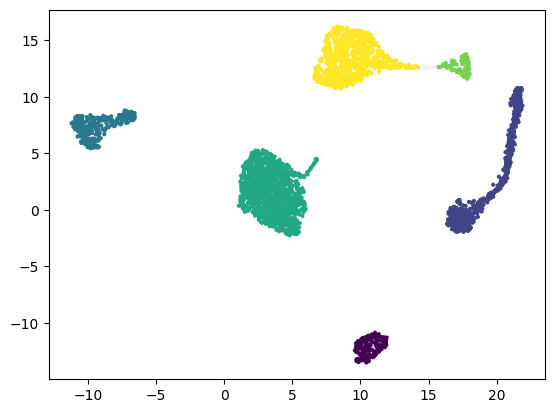

In [ ]:
# HDBSCAN can fail to cluster some data.  These get a label of -1. Let's remove them
clustered = (res_labels >= 0)

# Plot the non-clustered events in light grey and the clustered ones in colour:
plt.scatter(res[~clustered,0], res[~clustered,1], marker=".", linewidths=0.01, color=(0.95, 0.95, 0.95))
plt.scatter(res[clustered,0], res[clustered,1], marker=".", linewidths=0.01, c=(res_labels[clustered]))
plt.show()